# 10 — Time-Series Forecasting: Daily Order Volume

## Business objective
Forecast **how many orders will be placed each day over the next 14 days**, issued once a week. This supports short-term operational planning: customer-service staffing, warehouse and carrier capacity, and seller communication.

## Target and data
- **Target:** daily count of orders placed (by `purchase_date`, all statuses, from Gold `fact_orders`), 2017-01-01 to **2018-08-21**: the Q-11 candidate window, cut 10 days early because the final days are incomplete in the extract (section 0). That gives 598 consecutive days, with missing days counted as 0.
- **Why daily:** there are only 20 months and 88 weeks of history, too few to estimate yearly seasonality. Daily data has a strong and stable weekly cycle and enough observations.
- **No revenue target:** daily item revenue correlates 0.97 with order counts, and average order value is stable (Phase 8), so a revenue forecast would add little beyond orders × average order value.

## Context from Phase 8 (not repeated here)
Notebook 04 decomposed this series with STL: trend strength 0.73, weekly seasonality 0.22, and a Black Friday spike on 2017-11-24 (1,176 orders). Notebook 05 found strong weekday effects (Monday +16%, Saturday −25%; ε² = 0.53) and overdispersion (variance 17× Poisson). This notebook adds only what forecasting needs: stationarity, ACF/PACF, differencing, rolling statistics, models and evaluation.

## Validation design
- **Development:** 2017-01-01 to 2018-05-31 (516 days).
  - Configurations and model choice are evaluated on **12 weekly forecast origins in March–May 2018** (rolling origin, expanding window). Each origin forecasts 14 days using data up to that origin only.
  - The SARIMA order is chosen by AIC on data up to 2018-02-28, before the validation origins.
- **Final test:** 2018-06-01 to 2018-08-21, with 10 weekly origins (each forecasting 14 days), used once at the end. The series ends on 2018-08-21 because of an extraction artifact; see section 0. Models are refitted at each origin on all data observed up to it, as in operational use.
- **Metrics:**
  - **WAPE** (Σ|error| / Σ actual) is primary: scale-free, interpretable, and robust to zero days.
  - Also MAE, RMSE, sMAPE, bias (Σ error / Σ actual), and MAPE only when all actuals are above 0.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor
from sqlalchemy import text
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.database.connection import get_engine

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG = ROOT / "reports" / "forecasting" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED, H = 42, 14
START, DEV_END, END = pd.Timestamp("2017-01-01"), pd.Timestamp("2018-05-31"), pd.Timestamp("2018-08-21")   # END: see section 0

orders = pd.read_parquet(ROOT / "data" / "processed" / "analytical" / "fact_orders.parquet")
w = orders[orders["in_candidate_window"]]
y_full = w.groupby("purchase_date").size().reindex(pd.date_range(START, "2018-08-31", freq="D"), fill_value=0).astype(float).rename("orders")
y = y_full[:END].copy()
y.index.freq = "D"

# validation: continuity, aggregation = PostgreSQL view, split boundaries
with get_engine().connect() as c:
    sd = pd.read_sql(text("SELECT purchase_date, n_orders FROM analytics.sales_daily WHERE purchase_date BETWEEN :a AND :b"),
                     c, params={"a": START.date(), "b": pd.Timestamp("2018-08-31").date()}, index_col="purchase_date")
sd.index = pd.to_datetime(sd.index)
assert len(y) == (END - START).days + 1 and y.index.is_monotonic_increasing and y.index.to_series().diff().dropna().eq(pd.Timedelta("1D")).all()
assert (sd["n_orders"].reindex(y_full.index) == y_full).all(), "daily orders must equal analytics.sales_daily"
dev, test = y[:DEV_END], y[DEV_END + pd.Timedelta("1D"):]
VAL_ORIGINS = pd.date_range("2018-02-28", periods=12, freq="7D")      # forecasts cover 2018-03-01 .. 2018-05-30
TEST_ORIGINS = pd.date_range(DEV_END, END - pd.Timedelta(days=H), freq="7D")   # 10 weekly origins; forecasts cover 2018-06-01 .. 2018-08-16
assert (VAL_ORIGINS + pd.Timedelta(days=H)).max() <= DEV_END and (TEST_ORIGINS + pd.Timedelta(days=H)).max() <= END
print(f"Gold daily orders 2017-01-01..2018-08-31 equal analytics.sales_daily | modelled series {len(y)} days ({y.index.min().date()} .. {y.index.max().date()}) | "
      f"development {len(dev)} days, test {len(test)} days")
print(f"zero-order days: {y[y == 0].index.strftime('%Y-%m-%d').tolist()} | min in test period: {int(test.min())}")
print(f"validation origins {VAL_ORIGINS[0].date()}..{VAL_ORIGINS[-1].date()} | test origins {TEST_ORIGINS[0].date()}..{TEST_ORIGINS[-1].date()} | horizon {H} days")

Gold daily orders 2017-01-01..2018-08-31 equal analytics.sales_daily | modelled series 598 days (2017-01-01 .. 2018-08-21) | development 516 days, test 82 days
zero-order days: ['2017-01-01', '2017-01-02', '2017-01-03', '2017-01-04'] | min in test period: 91
validation origins 2018-02-28..2018-05-16 | test origins 2018-05-31..2018-08-02 | horizon 14 days


## 0. Data completeness at the end of the window
The last days of August 2018 aren't real demand: the extract stops capturing new orders.

daily orders, 2018-08-15 .. 2018-08-31: {'08-15': 288, '08-16': 320, '08-17': 257, '08-18': 198, '08-19': 204, '08-20': 256, '08-21': 243, '08-22': 187, '08-23': 144, '08-24': 99, '08-25': 69, '08-26': 73, '08-27': 67, '08-28': 44, '08-29': 14, '08-30': 4, '08-31': 1}
mean by weekday 2018-07-01..2018-08-21: {'Friday': 222.0, 'Monday': 263.0, 'Saturday': 176.0, 'Sunday': 189.0, 'Thursday': 247.0, 'Tuesday': 262.0, 'Wednesday': 268.0}


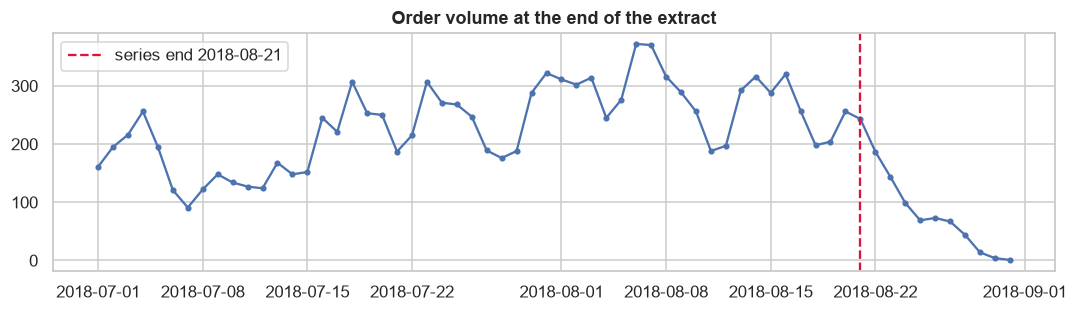

In [2]:
tail = y_full["2018-08-01":]
print("daily orders, 2018-08-15 .. 2018-08-31:", {f"{d:%m-%d}": int(v) for d, v in tail["2018-08-15":].items()})
print(f"mean by weekday 2018-07-01..2018-08-21: {y_full['2018-07-01':END].groupby(y_full['2018-07-01':END].index.day_name()).mean().round(0).to_dict()}")
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(y_full["2018-07-01":], marker="o", ms=3); ax.axvline(END, color="crimson", ls="--", label=f"series end {END.date()}")
ax.set(title="Order volume at the end of the extract"); ax.legend(); plt.tight_layout(); plt.show()

**Data-completeness finding.** Daily orders are at a normal level until **2018-08-21** (243–320 orders on weekdays). From 2018-08-22 they fall steadily: 187, 144, 99, … down to 14, 4 and 1 on the last three days. Every order in that final week is already delivered or canceled, and none is in transit. The extract evidently stops capturing new orders, so these days measure the **data cut-off, not demand**.

Phase 8's STL didn't flag this, because a decomposition absorbs a gradual decline into the trend. Forecasting those days would score models on a collection artifact. **The series therefore ends on 2018-08-21.** This decision rests only on data completeness; no model result influenced it.

## 1. Forecasting diagnostics: rolling statistics, stationarity, ACF/PACF

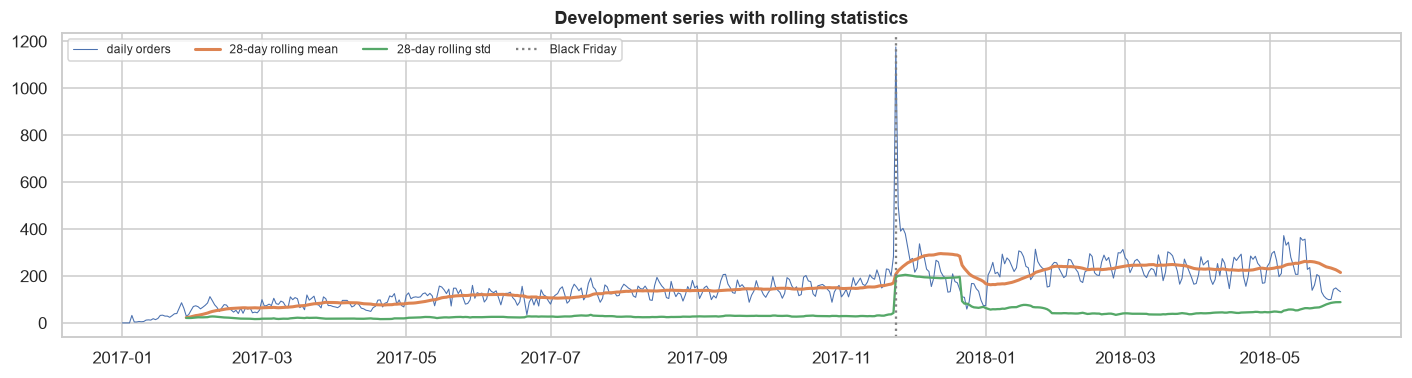

,ADF stat,ADF p,KPSS stat,KPSS p
series,,,,
orders,-2.872,0.049,2.697,0.010
log orders,-3.385,0.011,2.387,0.010
Δ log orders,-5.791,0.000,0.402,0.076
Δ Δ7 log orders,-9.234,0.000,0.232,0.100


28-day coefficient of variation: median 0.21 (std grows with the level -> log transform)


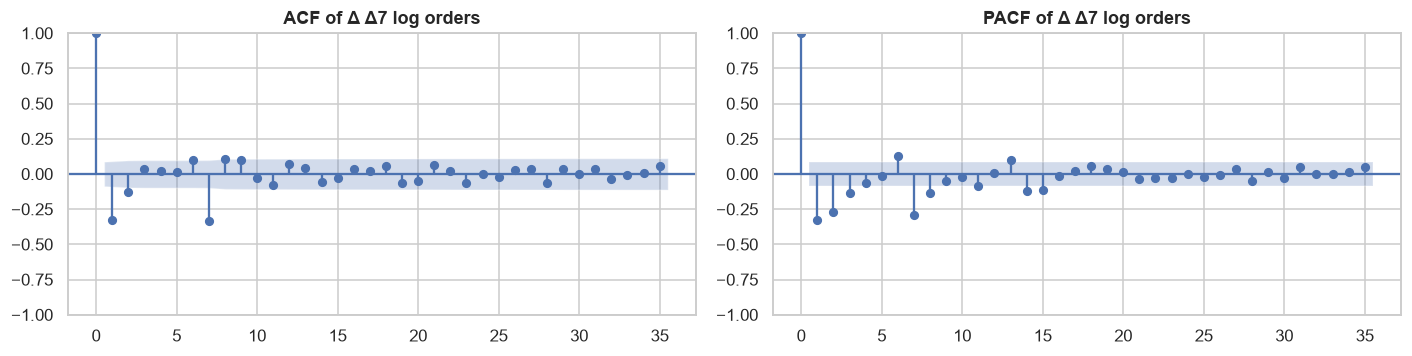

In [3]:
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.plot(dev, lw=.7, label="daily orders"); ax.plot(dev.rolling(28).mean(), lw=2, label="28-day rolling mean")
ax.plot(dev.rolling(28).std(), lw=1.5, label="28-day rolling std"); ax.axvline(pd.Timestamp("2017-11-24"), color="gray", ls=":", label="Black Friday")
ax.set(title="Development series with rolling statistics"); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

z = np.log1p(dev)                                     # log: stabilises the variance that grows with the level
def tests(s, name):
    a, k = adfuller(s.dropna(), autolag="AIC"), kpss(s.dropna(), regression="c", nlags="auto")
    return {"series": name, "ADF stat": a[0], "ADF p": a[1], "KPSS stat": k[0], "KPSS p": k[1]}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")                    # KPSS p-values are truncated to [0.01, 0.1]
    st = pd.DataFrame([tests(dev, "orders"), tests(z, "log orders"), tests(z.diff(), "Δ log orders"),
                       tests(z.diff().diff(7), "Δ Δ7 log orders")]).set_index("series")
display(st)
roll_cv = (dev.rolling(28).std() / dev.rolling(28).mean()).dropna()
print(f"28-day coefficient of variation: median {roll_cv.median():.2f} (std grows with the level -> log transform)")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
dz = z.diff().diff(7).dropna()
plot_acf(dz, lags=35, ax=ax[0], title="ACF of Δ Δ7 log orders"); plot_pacf(dz, lags=35, ax=ax[1], method="ywm", title="PACF of Δ Δ7 log orders")
plt.tight_layout(); plt.show()

**Interpretation:**
- **Rolling statistics:**
  - The 28-day mean rises from about 60 orders a day in early 2017 to more than 200 in 2018: a strong trend.
  - The 28-day standard deviation grows with the level, keeping a 28-day coefficient of variation of about 0.21. Variability is roughly proportional to volume, so the **log** scale is the appropriate one.
  - Black Friday is a single isolated spike.
- **Stationarity:**
  - **Level and log level:** the ADF test only weakly rejects a unit root (p = 0.049 and 0.011), and **KPSS rejects stationarity** (p ≤ 0.01). The tests conflict, which is typical of a trending series, so the level isn't treated as stationary.
  - **First difference of the log:** ADF rejects a unit root (p < 0.001), and KPSS no longer rejects stationarity (p = 0.076).
  - **Adding a weekly difference (Δ Δ7)** makes both tests agree clearly. One regular plus one seasonal difference (d = 1, D = 1, period 7) is therefore appropriate for SARIMA.
- **ACF / PACF of Δ Δ7 log orders:**
  - The ACF has significant negative spikes only at **lag 1 (−0.33) and lag 7 (−0.33)**, with small side lobes at lags 2, 6, 8 and 9.
  - The PACF decays across lags 1–3 and 7–8.
  - This is the classic signature of a non-seasonal MA(1) **plus a seasonal MA(1)** (the "airline model"). The AIC search below (SARIMA(2,1,2)×(0,1,1)₇) agrees with the seasonal MA(1) term.
- **Seasonality:** the weekly cycle is the only seasonality that can be estimated. There are fewer than two years of data, so yearly seasonality (for example Black Friday or Christmas) can't be modelled, which limits any forecast that crosses such dates.

## 2. Forecasting functions
Each function receives the history up to the forecast origin, **and only that history**, and returns the next 14 days.

In [4]:
def f_naive(hist):          return np.repeat(hist.iloc[-1], H)
def f_snaive(hist):         return np.tile(hist.iloc[-7:].to_numpy(), 2)[:H]            # same weekday last week
def f_ma28(hist):           return np.repeat(hist.iloc[-28:].mean(), H)

def f_hw(hist, trend="add", damped=True, log=True):
    s = np.log1p(hist) if log else hist
    m = ExponentialSmoothing(s, trend=trend, damped_trend=damped if trend else False, seasonal="add", seasonal_periods=7,
                             initialization_method="estimated").fit()
    fc = np.asarray(m.forecast(H))
    return np.clip(np.expm1(fc) if log else fc, 0, None)

def f_sarima(hist, order, sorder):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = SARIMAX(np.log1p(hist), order=order, seasonal_order=(*sorder, 7)).fit(disp=False)
    return np.clip(np.expm1(np.asarray(m.forecast(H))), 0, None)

# ---- ML: direct forecasting with horizon-safe features (every input is >= 14 days older than the target day)
def features(hist, horizon_end):
    s = hist.reindex(pd.date_range(hist.index[0], horizon_end, freq="D"))       # future days are NaN, never filled
    s14 = s.shift(H)
    X = pd.DataFrame({"lag14": s14, "lag21": s.shift(21), "lag28": s.shift(28),
                      "roll7_mean": s14.rolling(7).mean(), "roll28_mean": s14.rolling(28).mean(), "roll28_std": s14.rolling(28).std(),
                      "lag14_same_weekday_mean": (s.shift(14) + s.shift(21) + s.shift(28)) / 3,
                      "dow": s.index.day_of_week, "month": s.index.month, "day_of_month": s.index.day,
                      "trend": (s.index - START).days}, index=s.index)
    return X, s

def f_hgb(hist, **params):
    X, s = features(hist, hist.index[-1] + pd.Timedelta(days=H))
    train = X.index[(X.index <= hist.index[-1])]
    train = train[X.loc[train, ["lag28", "roll28_std"]].notna().all(axis=1)]
    m = HistGradientBoostingRegressor(loss="poisson", random_state=SEED, categorical_features=[X.columns.get_loc("dow")], **params)
    m.fit(X.loc[train], s.loc[train])
    future = X.index[X.index > hist.index[-1]]
    assert X.loc[future].drop(columns=["dow", "month", "day_of_month", "trend"]).notna().all().all(), "future features must be observable"
    return m.predict(X.loc[future])

# leakage test: features up to origin + 14 days are identical whether built from the full series or the truncated history
T = pd.Timestamp("2018-03-31")
Xa, _ = features(y[:T], T + pd.Timedelta(days=H)); Xb, _ = features(y, END)
assert np.allclose(Xa.to_numpy(dtype=float), Xb.loc[Xa.index].to_numpy(dtype=float), equal_nan=True)
print("leakage test passed: features for the 14 forecast days use only data up to the origin")

leakage test passed: features for the 14 forecast days use only data up to the origin


## 3. Rolling-origin evaluation helpers and metrics

In [5]:
def backtest(fn, origins, **kw):
    out = []
    for o in origins:
        fc = fn(y[:o], **kw)                                                     # history up to the origin only
        days = pd.date_range(o + pd.Timedelta(days=1), periods=H, freq="D")
        out.append(pd.DataFrame({"origin": o, "date": days, "h": range(1, H + 1), "actual": y.loc[days].to_numpy(), "forecast": fc}))
    return pd.concat(out, ignore_index=True)

def metrics(df):
    e, a = df["forecast"] - df["actual"], df["actual"]
    return {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()), "WAPE": e.abs().sum() / a.sum(),
            "sMAPE": (2 * e.abs() / (df["forecast"].abs() + a.abs()).replace(0, np.nan)).mean(),
            "MAPE": (e.abs() / a).mean() if (a > 0).all() else np.nan, "bias": e.sum() / a.sum()}

# metric check on a hand example
chk = metrics(pd.DataFrame({"actual": [10.0, 20.0], "forecast": [12.0, 15.0]}))
assert np.isclose(chk["MAE"], 3.5) and np.isclose(chk["WAPE"], 7 / 30) and np.isclose(chk["bias"], -3 / 30) and np.isclose(chk["MAPE"], (0.2 + 0.25) / 2)
print("metric functions verified on a hand-computed example")

metric functions verified on a hand-computed example


## 4. Model selection on development data (validation origins March–May 2018)

In [6]:
# SARIMA order: AIC grid on development data before the validation origins
fit_base = np.log1p(y[:VAL_ORIGINS[0]])
aic = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for p in (0, 1, 2):
        for q in (0, 1, 2):
            for P in (0, 1):
                for Q in (0, 1):
                    try:
                        r = SARIMAX(fit_base, order=(p, 1, q), seasonal_order=(P, 1, Q, 7)).fit(disp=False)
                        aic.append({"order": (p, 1, q), "seasonal": (P, 1, Q), "AIC": r.aic})
                    except Exception:
                        pass
aic = pd.DataFrame(aic).sort_values("AIC")
display(aic.head(5))
SAR_ORDER, SAR_SEASONAL = aic.iloc[0]["order"], aic.iloc[0]["seasonal"]
print(f"selected SARIMA{SAR_ORDER}x{SAR_SEASONAL}7 on log1p orders")

candidates = {
    "Naive": (f_naive, {}), "Seasonal naive (last week)": (f_snaive, {}), "Moving average 28d": (f_ma28, {}),
    "Holt-Winters log, damped trend": (f_hw, {"trend": "add", "damped": True, "log": True}),
    "Holt-Winters log, no trend": (f_hw, {"trend": None, "log": True}),
    "Holt-Winters raw, damped trend": (f_hw, {"trend": "add", "damped": True, "log": False}),
    f"SARIMA{SAR_ORDER}x{SAR_SEASONAL}7": (f_sarima, {"order": SAR_ORDER, "sorder": SAR_SEASONAL}),
    "HistGB lr=0.05 leaves=15": (f_hgb, {"learning_rate": 0.05, "max_leaf_nodes": 15, "max_iter": 300}),
    "HistGB lr=0.05 leaves=7": (f_hgb, {"learning_rate": 0.05, "max_leaf_nodes": 7, "max_iter": 300}),
    "HistGB lr=0.1 leaves=15": (f_hgb, {"learning_rate": 0.1, "max_leaf_nodes": 15, "max_iter": 200}),
}
val = {name: backtest(fn, VAL_ORIGINS, **kw) for name, (fn, kw) in candidates.items()}
val_tab = pd.DataFrame({n: metrics(d) for n, d in val.items()}).T.sort_values("WAPE")
display(val_tab)
FAMILY = {"Holt-Winters": [n for n in candidates if n.startswith("Holt-Winters")], "HistGB": [n for n in candidates if n.startswith("HistGB")]}
chosen = {fam: val_tab.loc[names, "WAPE"].idxmin() for fam, names in FAMILY.items()}
FINAL = ["Naive", "Seasonal naive (last week)", "Moving average 28d", chosen["Holt-Winters"], f"SARIMA{SAR_ORDER}x{SAR_SEASONAL}7", chosen["HistGB"]]
print("configurations chosen on validation:", chosen)

,order,seasonal,AIC
33,"(2, 1, 2)","(0, 1, 1)",106.261
35,"(2, 1, 2)","(1, 1, 1)",107.886
9,"(0, 1, 2)","(0, 1, 1)",112.030
11,"(0, 1, 2)","(1, 1, 1)",112.060
17,"(1, 1, 1)","(0, 1, 1)",112.340


selected SARIMA(2, 1, 2)x(0, 1, 1)7 on log1p orders


,MAE,RMSE,WAPE,sMAPE,MAPE,bias
HistGB lr=0.05 leaves=7,41.282,53.923,0.177,0.178,0.206,0.047
HistGB lr=0.05 leaves=15,41.719,53.150,0.179,0.180,0.203,0.040
HistGB lr=0.1 leaves=15,42.766,54.163,0.184,0.185,0.207,0.037
Seasonal naive (last week),44.286,63.417,0.190,0.187,0.226,0.052
"Holt-Winters log, damped trend",44.690,63.152,0.192,0.187,0.233,0.067
"Holt-Winters log, no trend",47.649,67.625,0.205,0.198,0.252,0.087
Moving average 28d,50.706,62.581,0.218,0.221,0.253,0.028
"Holt-Winters raw, damped trend",52.197,70.060,0.224,0.218,0.277,0.106
"SARIMA(2, 1, 2)x(0, 1, 1)7",56.933,81.188,0.244,0.231,0.298,0.101
Naive,69.869,90.952,0.300,0.281,0.382,0.205


configurations chosen on validation: {'Holt-Winters': 'Holt-Winters log, damped trend', 'HistGB': 'HistGB lr=0.05 leaves=7'}


**Validation results** (12 origins, March–May 2018, WAPE):
- **HistGradientBoosting is best:** 0.177 for the best configuration (learning rate 0.05, 7 leaves), against 0.190 for the seasonal naive.
- **Holt-Winters** on the log scale with a damped trend: 0.192, about level with the seasonal naive. The log, damped version clearly beats the raw-scale (0.224) and no-trend (0.205) versions, so it's carried forward.
- **SARIMA** (0.244) is worse than the seasonal naive despite its good in-sample AIC. Its trend extrapolation over 14 days adds error, as its positive bias (+10%) shows.
- **The 28-day moving average** (0.218) ignores the weekly cycle, and the **naive** forecast (0.300) is worst. Both confirm that the weekday pattern is essential.

**What was decided here, before the test:**
- one configuration per model family, by validation WAPE;
- **the model expected to do best is HistGradientBoosting.**

The validation gain over the seasonal naive is modest, about 7% (0.177 vs 0.190).

## 5. Final test: June–August 2018 (10 weekly origins × 14 days, evaluated once)

In [7]:
res = {name: backtest(candidates[name][0], TEST_ORIGINS, **candidates[name][1]) for name in FINAL}
test_tab = pd.DataFrame({n: metrics(d) for n, d in res.items()}).T
test_tab["WAPE vs seasonal naive"] = test_tab["WAPE"] / test_tab.loc["Seasonal naive (last week)", "WAPE"] - 1
display(test_tab.sort_values("WAPE"))
BEST_VAL = val_tab.loc[FINAL].drop(index=["Naive", "Seasonal naive (last week)", "Moving average 28d"])["WAPE"].idxmin()
print(f"model with the best validation WAPE (decided before the test): {BEST_VAL}")

# is the improvement over the seasonal naive consistent across origins? (paired by origin)
per_origin = pd.DataFrame({n: d.groupby("origin").apply(lambda g: (g["forecast"] - g["actual"]).abs().sum() / g["actual"].sum(), include_groups=False)
                           for n, d in res.items()})
wins = (per_origin[BEST_VAL] < per_origin["Seasonal naive (last week)"]).sum()
print(f"{BEST_VAL} beats the seasonal naive at {wins} of {len(per_origin)} test origins")
display(per_origin.round(3))

,MAE,RMSE,WAPE,sMAPE,MAPE,bias,WAPE vs seasonal naive
"Holt-Winters log, damped trend",47.438,61.374,0.214,0.243,0.233,-0.088,-0.069
Seasonal naive (last week),50.957,63.880,0.230,0.261,0.246,-0.100,0.000
HistGB lr=0.05 leaves=7,54.341,67.632,0.246,0.254,0.265,-0.054,0.066
Moving average 28d,56.891,70.120,0.257,0.265,0.265,-0.113,0.116
"SARIMA(2, 1, 2)x(0, 1, 1)7",57.326,73.914,0.259,0.307,0.284,-0.033,0.125
Naive,58.857,71.504,0.266,0.290,0.304,-0.021,0.155


model with the best validation WAPE (decided before the test): HistGB lr=0.05 leaves=7
HistGB lr=0.05 leaves=7 beats the seasonal naive at 3 of 10 test origins


,Naive,Seasonal naive (last week),Moving average 28d,"Holt-Winters log, damped trend","SARIMA(2, 1, 2)x(0, 1, 1)7",HistGB lr=0.05 leaves=7
origin,,,,,,
2018-05-31,0.372,0.415,0.138,0.404,0.562,0.169
2018-06-07,0.153,0.113,0.165,0.095,0.197,0.173
2018-06-14,0.143,0.125,0.183,0.067,0.183,0.143
2018-06-21,0.207,0.108,0.165,0.107,0.100,0.103
2018-06-28,0.567,0.382,0.389,0.390,0.423,0.443
2018-07-05,0.365,0.278,0.395,0.295,0.281,0.435
2018-07-12,0.464,0.465,0.262,0.474,0.591,0.304
2018-07-19,0.175,0.177,0.273,0.123,0.146,0.222
2018-07-26,0.222,0.178,0.329,0.184,0.108,0.324


**Final test (June 1 to August 21, 2018; 10 origins × 14 days):**

| Model | Test WAPE | vs seasonal naive | Bias |
|---|---:|---:|---:|
| Holt-Winters (log, damped trend) | **0.214** | **−6.9%** | −8.8% |
| Seasonal naive (last week) | 0.230 | – | −10.0% |
| HistGradientBoosting (selected on validation) | 0.246 | +6.6% | −5.4% |
| Moving average 28 days | 0.257 | +11.6% | −11.3% |
| SARIMA(2,1,2)×(0,1,1)₇ | 0.259 | +12.5% | −3.3% |
| Naive | 0.266 | +15.5% | −2.1% |

**Interpretation:**
- **The validation winner didn't hold up.** HistGradientBoosting was best on validation but is **6.6% worse than the seasonal naive** on test, and beats it at only 3 of 10 origins. Its validation advantage (about 7%) was within the range of period-to-period variation, so it wasn't a reliable signal. This is reported as it happened; the model isn't swapped after seeing the test.
- **Holt-Winters is the best test model:** 6.9% lower WAPE than the seasonal naive (MAE 47 vs 51 orders a day). That improvement is **modest and not consistent**: Holt-Winters beats the seasonal naive at **6 of 10 origins** and loses at 4.
- **The seasonal naive (same weekday last week) is a strong benchmark.** None of the more complex models beats it by a wide or consistent margin on this short, drifting series.
- **All models under-forecast** in the test period (bias −2% to −11%). Most of this comes from an unanticipated level shift: volume averaged about 205 orders a day in June and July, then **jumped to 277 in August 1–21** (largest misses: 2018-08-06/07, with 372 and 370 orders actual against about 203–212 forecast). No model using past data alone can predict such a shift.
- **MAPE is valid here** (the minimum test day has 91 orders) and ranks the models the same way as WAPE.

## 6. Forecast diagnostics on the test period

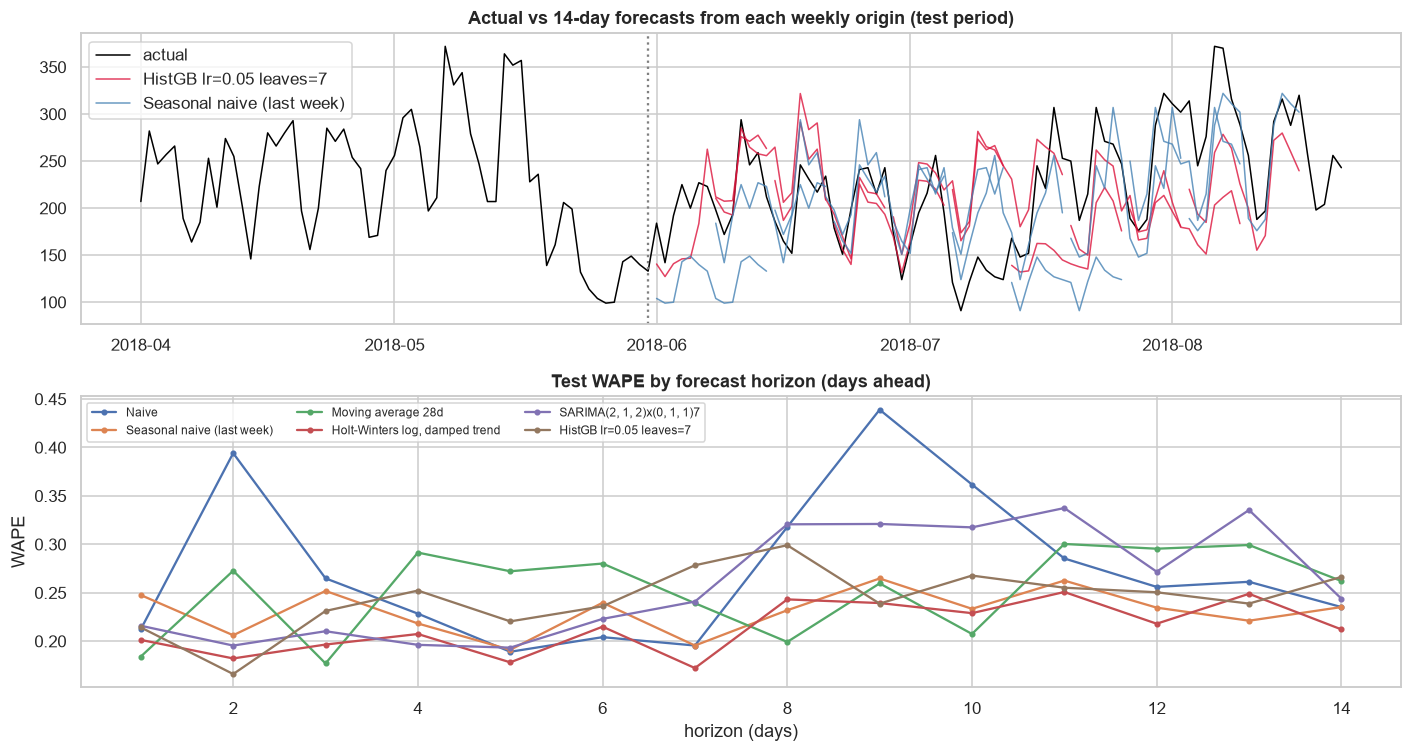

,Naive,Seasonal naive (last week),Moving average 28d,"Holt-Winters log, damped trend","SARIMA(2, 1, 2)x(0, 1, 1)7",HistGB lr=0.05 leaves=7
horizon (days),,,,,,
1,0.212,0.248,0.184,0.201,0.216,0.214
7,0.196,0.196,0.239,0.172,0.241,0.278
14,0.235,0.235,0.262,0.212,0.244,0.266


,mean error,MAE
date,,
Monday,-16.176,65.837
Tuesday,-12.805,59.238
Wednesday,-18.906,60.152
Thursday,-23.594,64.531
Friday,-2.597,51.451
Saturday,4.013,32.957
Sunday,-13.752,46.218


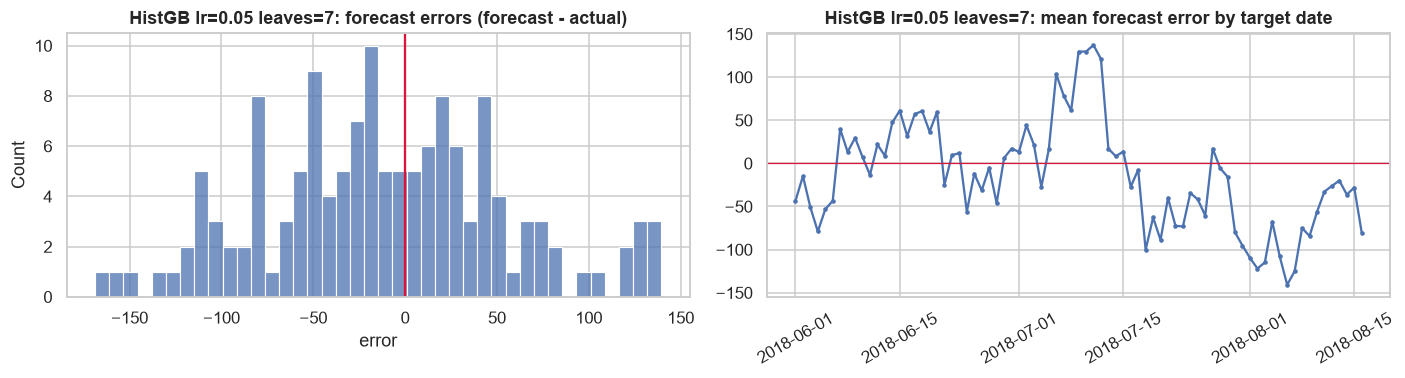

largest misses: [('2018-08-06', 372, 203), ('2018-08-07', 370, 212), ('2018-07-18', 307, 155)]


In [8]:
fig, ax = plt.subplots(2, 1, figsize=(13, 7))
ax[0].plot(y["2018-04-01":], color="black", lw=1, label="actual")
for n, c in ((BEST_VAL, "crimson"), ("Seasonal naive (last week)", "steelblue")):
    d = res[n]
    for i, (o, g) in enumerate(d.groupby("origin")):
        ax[0].plot(g["date"], g["forecast"], color=c, lw=1, alpha=.8, label=n if i == 0 else None)
ax[0].axvline(DEV_END, color="gray", ls=":"); ax[0].set(title="Actual vs 14-day forecasts from each weekly origin (test period)"); ax[0].legend()
byh = pd.DataFrame({n: d.groupby("h").apply(lambda g: (g["forecast"] - g["actual"]).abs().sum() / g["actual"].sum(), include_groups=False)
                    for n, d in res.items()})
byh.plot(ax=ax[1], marker="o", ms=3); ax[1].set(title="Test WAPE by forecast horizon (days ahead)", xlabel="horizon (days)", ylabel="WAPE")
ax[1].legend(fontsize=8, ncol=3)
plt.tight_layout(); plt.savefig(FIG / "forecast_test.png", bbox_inches="tight"); plt.show()
display(byh.loc[[1, 7, 14]].round(3).rename_axis("horizon (days)"))

r = res[BEST_VAL].assign(error=lambda d: d["forecast"] - d["actual"])
by_dow = r.groupby(r["date"].dt.day_name())["error"].agg(["mean", lambda e: e.abs().mean()]).rename(columns={"mean": "mean error", "<lambda_0>": "MAE"})
display(by_dow.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
sns.histplot(r["error"], bins=40, ax=ax[0]); ax[0].axvline(0, color="crimson"); ax[0].set(title=f"{BEST_VAL}: forecast errors (forecast - actual)")
daily_err = r.groupby("date")["error"].mean()
ax[1].plot(daily_err.index, daily_err.values, marker="o", ms=2); ax[1].axhline(0, color="crimson", lw=.8)
ax[1].set(title=f"{BEST_VAL}: mean forecast error by target date"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
big = r.loc[r['error'].abs().nlargest(3).index]
print('largest misses:', [(f"{d:%Y-%m-%d}", int(a), int(round(f))) for d, a, f in zip(big['date'], big['actual'], big['forecast'])])

**Interpretation:**
- **Error by horizon:** errors don't grow much with the horizon. Holt-Winters has a WAPE of 0.20 at 1 day, 0.17 at 7 days and 0.21 at 14 days. Over two weeks, uncertainty is dominated by **level shifts and events**, not by the distance from the forecast origin.
- **By weekday** (HistGradientBoosting): under-forecasting is largest Monday to Thursday (−13 to −24 orders a day), when volume is highest, and smallest on Saturday (+4).
- **Error over time:** the errors cluster in a few periods: the early-July origins (WAPE about 0.26–0.59 across models) and the August surge. The errors are periods of collective miss, not random noise around a correct level.

**Practical reading:**
- For a 14-day operational plan, a **weekday-seasonal baseline or Holt-Winters** gives an expected error of roughly ±21–23% of daily volume.
- Plans should carry a buffer and be **updated weekly**.
- Known events (campaigns, holidays, Black Friday) must be added by planners, because the history is too short to learn them.

## 7. Summary

| Item | Result |
|---|---|
| Target | daily orders placed (Gold `fact_orders`, all statuses), 2017-01-01 to 2018-08-21; equal to `analytics.sales_daily` |
| Horizon / cadence | 14 days ahead, issued weekly (rolling origin, expanding window) |
| Validation | 12 origins in March–May 2018 (tuning and choice); final test of 10 origins in June–August 2018, used once |
| Leakage control | each model sees only history up to its origin; the ML features use data ≥ 14 days old (tested: identical from full and truncated series) |
| Validation winner | HistGradientBoosting: WAPE 0.177 vs 0.190 for the seasonal naive |
| Test result | **Holt-Winters best: WAPE 0.214 (−6.9% vs seasonal naive, better at 6 of 10 origins)**; HistGradientBoosting 0.246 (+6.6%, wins 3 of 10 origins); SARIMA 0.259 |
| Key lesson | the seasonal naive is hard to beat; gains are modest and not consistent across origins; level shifts dominate the error |

**Business implications:**
1. Use a **weekday-seasonal model (Holt-Winters, or the seasonal naive as a fallback)** for 14-day operational planning. Expect about ±21–23% daily error, and re-forecast weekly.
2. **Add known events manually.** Fewer than two years of history means yearly effects (Black Friday, Christmas) can't be learned.
3. **Monitor for level shifts.** The August 2018 surge (+36% over June–July) was invisible to all models. A simple alert when actuals exceed the forecast band for several days would trigger re-planning.

**Limitations:**
- **Short history:** 20 months, so no yearly seasonality, holidays or campaign data.
- **Small test:** 10 origins (about 11 weeks), so model differences of a few percent aren't statistically robust.
- **Data:** the extract ends early (truncated after 2018-08-21).
- **Out of scope:** forecasts are point forecasts, so prediction intervals aren't evaluated; revenue and category forecasts aren't modelled (revenue ≈ orders × a stable average order value).